In [ ]:
!pip install "numpy<2"
!pip install scikit-learn-extra kmodes
!pip install fuzzy-c-means

  Using cached scikit-learn-extra-0.3.0.tar.gz (818 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp312-cp312-linux_x86_64.whl size=2177963 sha256=86d3b73e4ad12e7fbaaacaf1e5ae7074ba58ce382ea7289681f035c5c8816859
  Stored in directory: /root/.cache/pip/wheels/17/4d/c3/c6d5d563c1bf8146d059d63be3678abc2f2801fba0aaf5f0b8
Successfully built scikit-learn-extra
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.6 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.17.4
    Uninstalling typer-0.17.4:
      Successfully uninstalled typer-0.17.4
  Attempting uninstall: tabulate
    Found existing installation: tabulate 0.9.0
    Uninstalling tabulate-0.9.0:
      Successfully uninstalled tabulate-0.9.0
ERROR: pip's dependency resolver does not currently take into account all the packages 

In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from kmodes.kmodes import KModes
from kmodes.kprototypes import KPrototypes
from sklearn.cluster import DBSCAN
from fcmeans import FCM

Pada laporan praktikum, sisipkan penjelasan singkat mengenai:
- Library `sklearn` (https://scikit-learn.org/stable/)
- Library `sklearn_extra` (https://scikit-learn-extra.readthedocs.io/en/stable/)
- Library `kmodes` (https://pypi.org/project/kmodes/)
- Library `fcmeans` (https://fuzzy-c-means.readthedocs.io/en/latest/)

Sisipkan penjelasan library di atas di **BAB 2** pada bagian metode yang sesuai. Gunakan *website* dokumentasi resminya sebagai referensi.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('drive/MyDrive/sml')

In [ ]:
df_full = pd.read_csv("transport.csv")
df_full.head()

,Daily Distance (km),Average Travel Time (min),Main Transport Mode,Monthly Cost (USD),Trips per Week,Owns Private Vehicle,Gender,City Type,Income Level,Job Sector
0,15.993428,44.691419,Motorcycle,540.951919,NaN,0.0,1.0,Urban,1.0,Education
1,14.723471,37.419776,Motorcycle,790.638953,10.0,1.0,1.0,Urban,1.0,Manufacturing
2,16.295377,40.480604,Motorcycle,805.405062,17.0,0.0,1.0,Urban,3.0,Manufacturing
3,18.046060,37.688624,Motorcycle,941.789104,9.0,1.0,1.0,Urban,3.0,Healthcare
4,14.531693,37.827519,Motorcycle,389.942491,NaN,1.0,1.0,Suburban,2.0,Healthcare


- Daily Distance (km): average kilometers traveled per day
- Monthly Cost (USD): monthly transportation expenses
- Average Travel Time (min): daily average time spent traveling
- Trips per Week: number of trips made in a week
- Owns Private Vehicle: ownership status (1 = yes, 0 = no)
- Main Transport Mode: main mode used (Motorcycle, Car, Bus, Bicycle)
- Gender: (0 = Male or 1 = Female)
- City Type: area type (Urban, Suburban, Rural)
- Income Level: income group coded as numbers (1 = Low, 2 = Lower-middle, 3 = Upper-middle, 4 = High)
- Job Sector: employment sector (IT, Healthcare, Education, Finance, Manufacturing)

Melihat struktur data mentah

In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Daily Distance (km)        1900 non-null   float64
 1   Average Travel Time (min)  1889 non-null   float64
 2   Main Transport Mode        1904 non-null   object 
 3   Monthly Cost (USD)         1903 non-null   float64
 4   Trips per Week             1881 non-null   float64
 5   Owns Private Vehicle       1913 non-null   float64
 6   Gender                     1890 non-null   float64
 7   City Type                  1907 non-null   object 
 8   Income Level               1893 non-null   float64
 9   Job Sector                 1914 non-null   object 
dtypes: float64(7), object(3)
memory usage: 156.4+ KB


Pemilihan variabel

In [ ]:
df = df_full.copy()
# df = df_full[['Daily Distance (km)', 'Monthly Cost (USD)', 'Owns Private Vehicle']]
df = df_full[['Daily Distance (km)', 'Average Travel Time (min)', 'Gender', 'Main Transport Mode']]
df.head()

,Daily Distance (km),Average Travel Time (min),Gender,Main Transport Mode
0,15.993428,44.691419,1.0,Motorcycle
1,14.723471,37.419776,1.0,Motorcycle
2,16.295377,40.480604,1.0,Motorcycle
3,18.046060,37.688624,1.0,Motorcycle
4,14.531693,37.827519,1.0,Motorcycle


Mempersingkat nama kolom

In [ ]:
df.columns = [
    'daily_distance',
    'avg_travel_time',
    'gender',
    'main_transport',
    ]
df.head()

,daily_distance,avg_travel_time,gender,main_transport
0,15.993428,44.691419,1.0,Motorcycle
1,14.723471,37.419776,1.0,Motorcycle
2,16.295377,40.480604,1.0,Motorcycle
3,18.046060,37.688624,1.0,Motorcycle
4,14.531693,37.827519,1.0,Motorcycle


Mengubah data kategorik yang terbaca numerik oleh Python

In [ ]:
df = df.copy()
for c in ["gender"]:
    df[c] = df[c].fillna(df[c].mode()[0]).astype(int).astype("category")

# EXPLORATORY DATA ANALYSIS

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   daily_distance   1900 non-null   float64 
 1   avg_travel_time  1889 non-null   float64 
 2   gender           2000 non-null   category
 3   main_transport   1904 non-null   object  
dtypes: category(1), float64(2), object(1)
memory usage: 49.1+ KB


In [ ]:
df.describe(include = 'number')

,daily_distance,avg_travel_time
count,1900.000000,1889.000000
mean,20.020572,52.261153
std,10.086841,23.446739
min,2.070551,12.829087
25%,13.570821,37.131500
50%,17.102162,46.278781
75%,27.554101,65.090585
max,46.778713,108.560326


In [ ]:
df.describe(include = ['category', 'object'])

,gender,main_transport
count,2000,1904
unique,2,4
top,1,Motorcycle
freq,1068,766


# PREPROCESSING

### Missing Value

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
daily_distance     100
avg_travel_time    111
gender               0
main_transport      96
dtype: int64


In [ ]:
df_lengkap = df.copy()

Jika terdapat missing value pada data, maka terdapat dua opsi untuk menanganinya:


1. Imputasi pada sel data yang kosong dengan suatu nilai (misal: mean/median/modus) pada kolom yang mengandung missing value

In [ ]:
# # 1. Contoh penanganan missing value menggunakan mean
# df_lengkap['(nama variabel yang terdeteksi missing value)'] = df_lengkap['(nama variabel yang terdeteksi missing value)'].fillna(df_lengkap['(nama variabel yang terdeteksi missing value)'].mean())
# df_lengkap['daily_distance'] = df_lengkap['daily_distance'].fillna(df_lengkap['daily_distance'].mean())
# df_lengkap['avg_travel_time'] = df_lengkap['avg_travel_time'].fillna(df_lengkap['avg_travel_time'].mean())

2. Menghapus baris yang mengandung missing value

In [ ]:
# 2. Contoh penanganan missing value dengan menghapus baris yang mengandung missing value
df_lengkap = df_lengkap.dropna(axis=0)

### Outlier

In [ ]:
def cek_outlier(df, kolom=None):
  num_cols = df.select_dtypes(include=[np.number]).columns
  if kolom is None:
    kolom = num_cols
  else:
    kolom = [c for c in kolom if c in num_cols]  # filter khusus numerik

  df_checked = df[kolom]
  df_checked.plot(
    kind="box",
    subplots=True,
    layout=(1, len(kolom)),
    figsize=(len(kolom) * 3, 5),
    sharey=False
  )

  plt.suptitle("Cek Outlier Semua Kolom")
  plt.show()

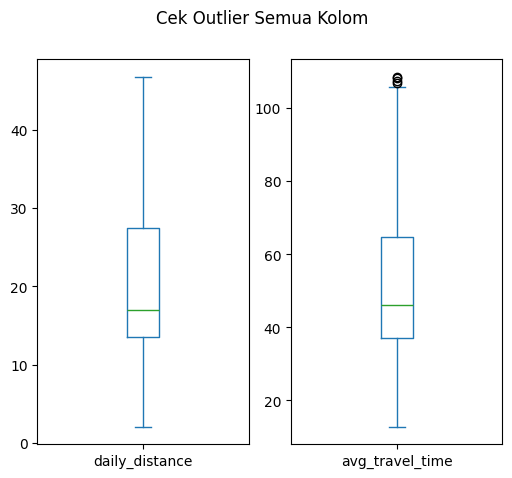

In [ ]:
cek_outlier(df_lengkap)

Hapus outlier (hanya gunakan jika diperlukan)

In [ ]:
def hapus_outlier(df, kolom=None, max_iter=1):
    num_cols = df.select_dtypes(include=[np.number]).columns
    if kolom is None:
        kolom = num_cols
    else:
        kolom = [c for c in kolom if c in num_cols]  # hanya numerik

    df_clean = df.copy()
    for i in range(max_iter):
        before = df_clean.shape[0]

        mask = pd.Series(True, index=df_clean.index)
        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            mask &= df_clean[c].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

        df_clean = df_clean[mask]
        after = df_clean.shape[0]

        if before == after:  # berhenti kalau tidak ada perubahan
            break

        print(f'Iterasi {i+1}: {before} -> {after} sampel')


    return df_clean

In [ ]:
df_bersih = df_lengkap.copy()
df_bersih = hapus_outlier(df_bersih, max_iter=10)
df_bersih.info()

Iterasi 1: 1703 -> 1699 sampel
<class 'pandas.core.frame.DataFrame'>
Index: 1699 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   daily_distance   1699 non-null   float64 
 1   avg_travel_time  1699 non-null   float64 
 2   gender           1699 non-null   category
 3   main_transport   1699 non-null   object  
dtypes: category(1), float64(2), object(1)
memory usage: 54.9+ KB


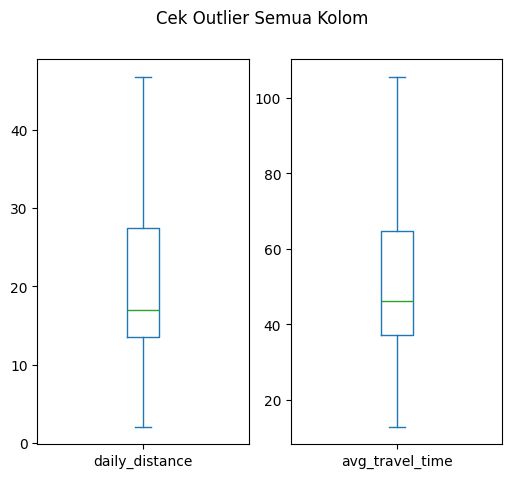

In [ ]:
cek_outlier(df_bersih)

### Data Duplikat

In [ ]:
print(df_bersih.duplicated().sum(), 'baris terduplikat')
display(df_bersih[df_bersih.duplicated()].head())

0 baris terduplikat


,daily_distance,avg_travel_time,gender,main_transport


Hapus data yang terduplikat

In [ ]:
df_siap = df_bersih.copy()
df_siap.drop_duplicates(inplace=True)
df_siap.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1699 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   daily_distance   1699 non-null   float64 
 1   avg_travel_time  1699 non-null   float64 
 2   gender           1699 non-null   category
 3   main_transport   1699 non-null   object  
dtypes: category(1), float64(2), object(1)
memory usage: 54.9+ KB


# CLUSTERING

In [ ]:
from sklearn.metrics import silhouette_score

## K-Means

In [ ]:
# Menyeleksi variabel numerik
df_kmeans = df_siap[['daily_distance', 'avg_travel_time']]
df_kmeans.head()

,daily_distance,avg_travel_time
0,15.993428,44.691419
1,14.723471,37.419776
2,16.295377,40.480604
3,18.046060,37.688624
4,14.531693,37.827519


2 kluster (K-Means): 0.5913
3 kluster (K-Means): 0.5351
4 kluster (K-Means): 0.6658
5 kluster (K-Means): 0.6214
6 kluster (K-Means): 0.5239
7 kluster (K-Means): 0.4849
8 kluster (K-Means): 0.4830
9 kluster (K-Means): 0.4587
10 kluster (K-Means): 0.4369


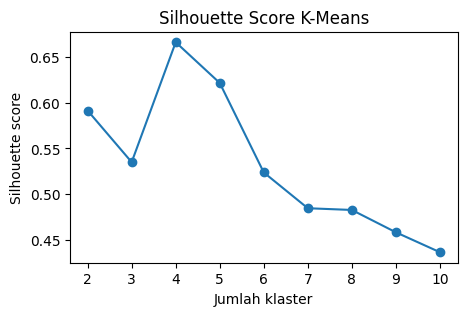

In [ ]:
scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=123)
    labels = kmeans.fit_predict(df_kmeans)
    s = silhouette_score(df_kmeans, labels)
    scores.append(s)
    print(f"{k} kluster (K-Means): {s:.4f}")

plt.figure(figsize=(5, 3))
plt.plot(k_range, scores, 'o-')
plt.title("Silhouette Score K-Means")
plt.xlabel("Jumlah klaster")
plt.ylabel("Silhouette score")
plt.show()

In [ ]:
# Membangun model
# n_cluster = 2 (silhouette score tertinggi)
kmeans = KMeans(n_clusters = 3, random_state = 123)

# Melatih model
df_kmeans = df_kmeans.copy()
df_kmeans['Klaster'] = kmeans.fit_predict(df_kmeans)

In [ ]:
# Melihat jumlah anggota setiap klaster
df_kmeans.head()

,daily_distance,avg_travel_time,Klaster
0,15.993428,44.691419,1
1,14.723471,37.419776,1
2,16.295377,40.480604,1
3,18.046060,37.688624,1
4,14.531693,37.827519,1


In [ ]:
# Mengecek jumlah anggota setiap klaster
df_kmeans['Klaster'].value_counts()

,count
Klaster,
1,997
0,366
2,336


Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Means')

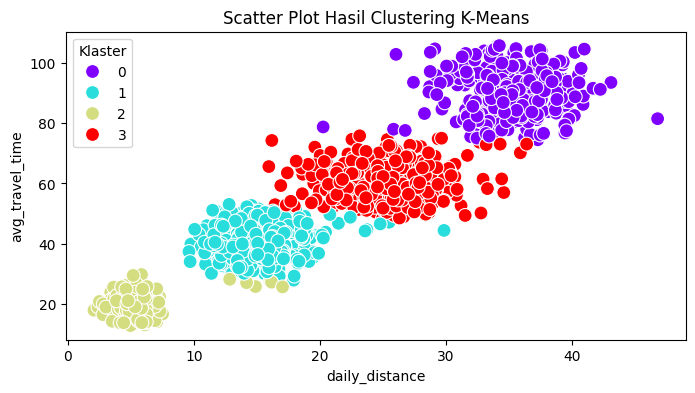

In [ ]:
# Memvisualisasikan hasil clustering
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kmeans,
    x = 'daily_distance',
    y = 'avg_travel_time',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Means') # s = 100 adalah untuk mengatur ukuran titik plot

## K-Medoids

In [ ]:
# Menyeleksi hanya variabel numerik
df_kmed = df_siap[['daily_distance', 'avg_travel_time']]
df_kmed.head()

,daily_distance,avg_travel_time
0,15.993428,44.691419
1,14.723471,37.419776
2,16.295377,40.480604
3,18.046060,37.688624
4,14.531693,37.827519


2 kluster (K-Medoids): 0.5912
3 kluster (K-Medoids): 0.5617
4 kluster (K-Medoids): 0.6660
5 kluster (K-Medoids): 0.5641
6 kluster (K-Medoids): 0.5220
7 kluster (K-Medoids): 0.5111
8 kluster (K-Medoids): 0.4648
9 kluster (K-Medoids): 0.4589
10 kluster (K-Medoids): 0.4584


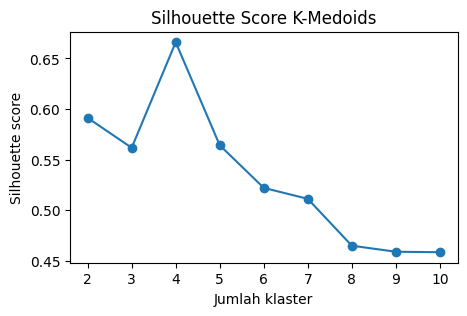

In [ ]:
scores = []
k_range = range(2, 11)

for k in k_range:
    kmedoids = KMedoids(n_clusters=k, random_state=123)
    labels = kmedoids.fit_predict(df_kmed)
    s = silhouette_score(df_kmed, labels)
    scores.append(s)
    print(f"{k} kluster (K-Medoids): {s:.4f}")

plt.figure(figsize=(5, 3))
plt.plot(k_range, scores, 'o-')
plt.title("Silhouette Score K-Medoids")
plt.xlabel("Jumlah klaster")
plt.ylabel("Silhouette score")
plt.show()

In [ ]:
# Membangun model
kmedoids = KMedoids(n_clusters = 3, random_state = 123)

# Melatih model
df_kmed = df_kmed.copy()
df_kmed['Klaster'] = kmedoids.fit_predict(df_kmed)

In [ ]:
# Melihat jumlah anggota setiap klaster
df_kmed['Klaster'].value_counts()

,count
Klaster,
0,1030
1,404
2,265


Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Medoids')

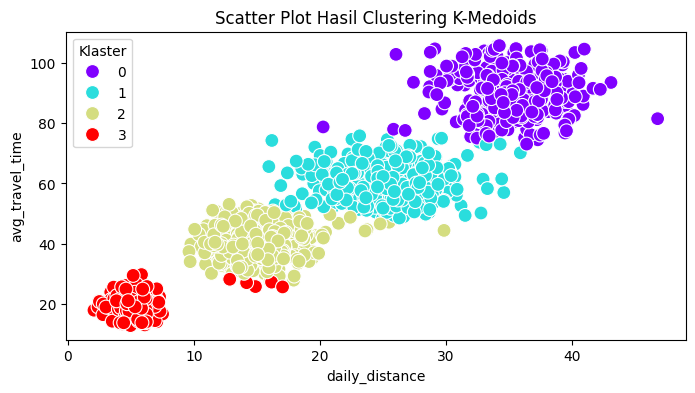

In [ ]:
# Memvisualisasikan hasil clustering
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kmed,
    x = 'daily_distance',
    y = 'avg_travel_time',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Medoids')

## K-Modes

In [ ]:
# Menyeleksi variabel kategorik
df_kmodes = df_siap[['gender', 'main_transport']]
df_kmodes.head()

,gender,main_transport
0,1,Motorcycle
1,1,Motorcycle
2,1,Motorcycle
3,1,Motorcycle
4,1,Motorcycle


In [ ]:
# Membangun model
kmodes = KModes(n_clusters = 2, random_state = 123)

# Melatih model
df_kmodes = df_kmodes.copy()
df_kmodes['Klaster'] = kmodes.fit_predict(df_kmodes)

In [ ]:
# Melihat jumlah anggota setiap klaster
df_kmodes['Klaster'].value_counts()

,count
Klaster,
0,1238
1,461


Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Modes')

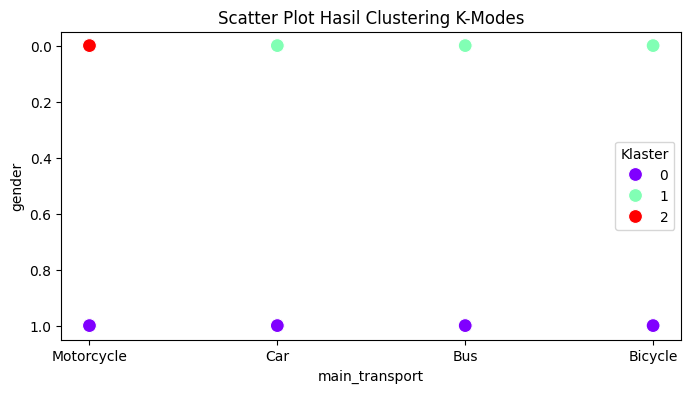

In [ ]:
# Memvisualisasikan hasil clustering
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kmodes,
    x = 'main_transport',
    y = 'gender',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Modes')

## K-Prototype

In [ ]:
df_kpro = df_siap.copy()
print(list(enumerate(df_kpro.columns)))
df_kpro.head()

[(0, 'daily_distance'), (1, 'avg_travel_time'), (2, 'gender'), (3, 'main_transport')]


,daily_distance,avg_travel_time,gender,main_transport
0,15.993428,44.691419,1,Motorcycle
1,14.723471,37.419776,1,Motorcycle
2,16.295377,40.480604,1,Motorcycle
3,18.046060,37.688624,1,Motorcycle
4,14.531693,37.827519,1,Motorcycle


In [ ]:
# Membangun model
kprototype = KPrototypes(n_clusters = 4, random_state = 123)

# Melatih model
df_kpro = df_kpro.copy()
df_kpro['Klaster'] = kprototype.fit_predict(df_kpro, categorical=[2, 3]) # [2, 3] adalah index dari variabel kategorik

In [ ]:
# Melihat jumlah anggota setiap klaster
df_kpro['Klaster'].value_counts()

,count
Klaster,
1,690
2,423
3,326
0,260


Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Prototype')

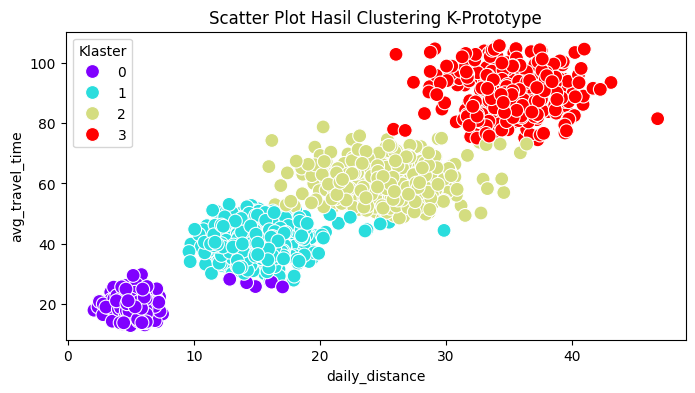

In [ ]:
# Memvisualisasikan hasil clustering untuk numerik
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kpro,
    x = 'daily_distance',
    y = 'avg_travel_time',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Prototype')

Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Prototype')

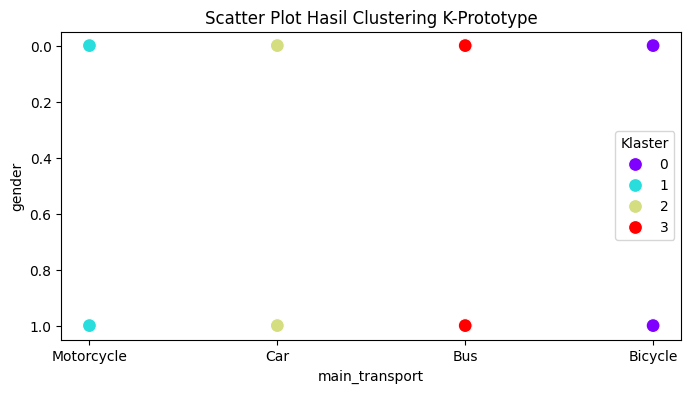

In [ ]:
# Memvisualisasikan hasil clustering untuk kategorik
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kpro,
    x = 'main_transport',
    y = 'gender',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Prototype')

Text(0.5, 1.0, 'Scatter Plot Hasil Clustering K-Prototype')

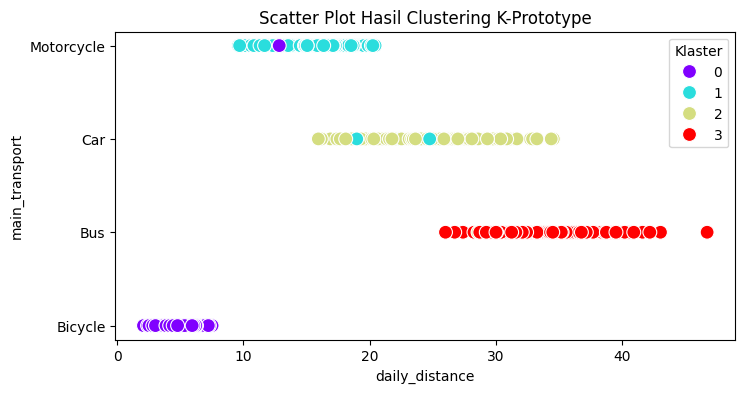

In [ ]:
# Memvisualisasikan hasil clustering untuk numerik dan kategorik
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_kpro,
    x = 'daily_distance',
    y = 'main_transport',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering K-Prototype')

## Fuzzy C-Means

In [ ]:
# Menyeleksi variabel numerik
df_fcm = df_siap[['daily_distance', 'avg_travel_time']]
df_fcm.head()

,daily_distance,avg_travel_time
0,15.993428,44.691419
1,14.723471,37.419776
2,16.295377,40.480604
3,18.046060,37.688624
4,14.531693,37.827519


2 kluster: 0.5865
3 kluster: 0.5557
4 kluster: 0.6656
5 kluster: 0.5924
6 kluster: 0.5563
7 kluster: 0.4965
8 kluster: 0.4706
9 kluster: 0.4507
10 kluster: 0.4044


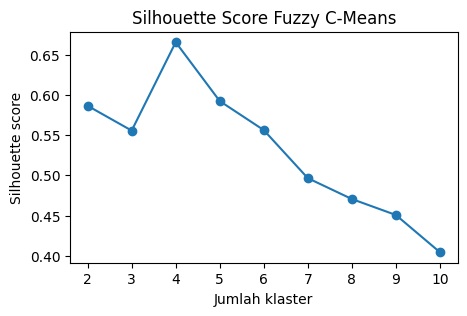

In [ ]:
scores = []
k_range = range(2, 11)

for k in k_range:
    fcm = FCM(n_clusters=k, random_state=123)
    fcm.fit(df_fcm.values)
    labels = fcm.predict(df_fcm.values)   # hasil klaster "keras"
    s = silhouette_score(df_fcm.values, labels)
    scores.append(s)
    print(f"{k} kluster: {s:.4f}")

plt.figure(figsize=(5, 3))
plt.plot(k_range, scores, 'o-')
plt.title("Silhouette Score Fuzzy C-Means")
plt.xlabel("Jumlah klaster")
plt.ylabel("Silhouette score")
plt.show()

In [ ]:
# Membangun model
fcm = FCM(n_clusters = 4, random_state = 123)

# Melatih model
fcm.fit(df_fcm.values)
df_fcm = df_fcm.copy()
df_fcm['Klaster'] = fcm.predict(df_fcm.values)

In [ ]:
# Mengecek jumlah anggota setiap klaster
df_fcm['Klaster'].value_counts()

,count
Klaster,
0,689
3,424
1,325
2,261


Text(0.5, 1.0, 'Scatter Plot Hasil Clustering Fuzzy C-Means')

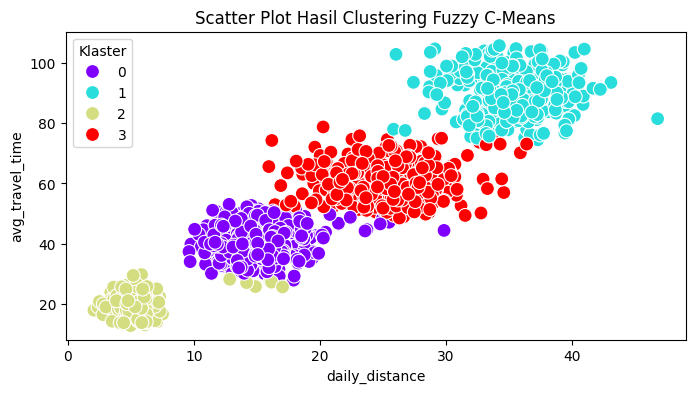

In [ ]:
# Memvisualisasikan hasil clustering untuk numerik
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_fcm,
    x = 'daily_distance',
    y = 'avg_travel_time',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 100
).set_title('Scatter Plot Hasil Clustering Fuzzy C-Means')

## DBSCAN

In [ ]:
# Menyeleksi variabel numerik
df_dbs = df_siap[['daily_distance', 'avg_travel_time']]
df_dbs.head()

,daily_distance,avg_travel_time
0,15.993428,44.691419
1,14.723471,37.419776
2,16.295377,40.480604
3,18.046060,37.688624
4,14.531693,37.827519


In [ ]:
# Membangun model
dbscan = DBSCAN(eps=2, min_samples=10)
# sesuaikan eps dan min_samples sesuai kebutuhan
# eps         : parameter yg menentukan jarak maks antara dua sampel utk dianggap sbg anggota klaster yg sama
# min_samples : parameter yg menentukan jumlah min sampel data dalam lingkungan eps utk mmbentuk sebuah klaster

# Melatih model
df_dbs = df_dbs.copy()
df_dbs['Klaster'] = dbscan.fit_predict(df_dbs)

In [ ]:
# Melihat jumlah anggota setiap klaster
df_dbs['Klaster'].value_counts()

,count
Klaster,
0,791
1,465
2,342
3,298
-1,98


Dalam DBSCAN, klaster -1 berarti titik tersebut dianggap **noise atau outlier** yang tidak masuk ke klaster manapun.

Text(0.5, 1.0, 'Scatter Plot Hasil Clustering DBSCAN')

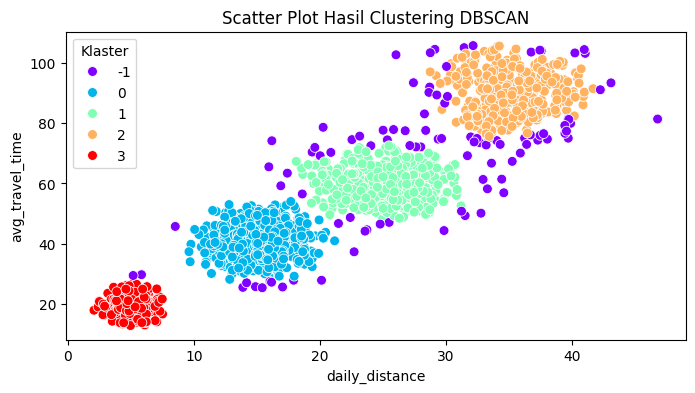

In [ ]:
# Memvisualisasikan hasil clustering
plt.figure(figsize = (8, 4))
sns.scatterplot(
    data = df_dbs,
    x = 'daily_distance',
    y = 'avg_travel_time',
    hue = 'Klaster',
    palette = 'rainbow',
    s = 50
).set_title('Scatter Plot Hasil Clustering DBSCAN')